# Chapter 6 · $L^p$ spaces, laws and densities: interactive demos

Companion to Chapter 6 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/06-laws-densities.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.laws import (MixedLaw, DiscreteLaw, binomial_law, dkw_epsilon, ecdf, expectation_density,
                            image_measure, integral, is_absolutely_continuous, ks_distance, poisson_law,
                            power_lp_norm, quantile, radon_nikodym)
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. $\|f\|_p$ as a function of $p$

For $f_a(x)=x^{-a}$ with Lebesgue measure, $\|f_a\|_p^p=\int x^{-ap}\,dx$. On $(0,1)$ this is finite exactly when
$ap<1$, on $(1,\infty)$ exactly when $ap>1$, and on $(0,\infty)$ never: the inclusions
$L^q\subseteq L^p$ ($p<q$) of Proposition 6.8 need $\mu(X)<\infty$. On the probability space $(0,1)$ the curve
$p\mapsto\|f\|_p$ is non-decreasing and tends to $\|f\|_\infty$; the bounded function $2x$ is shown for comparison.

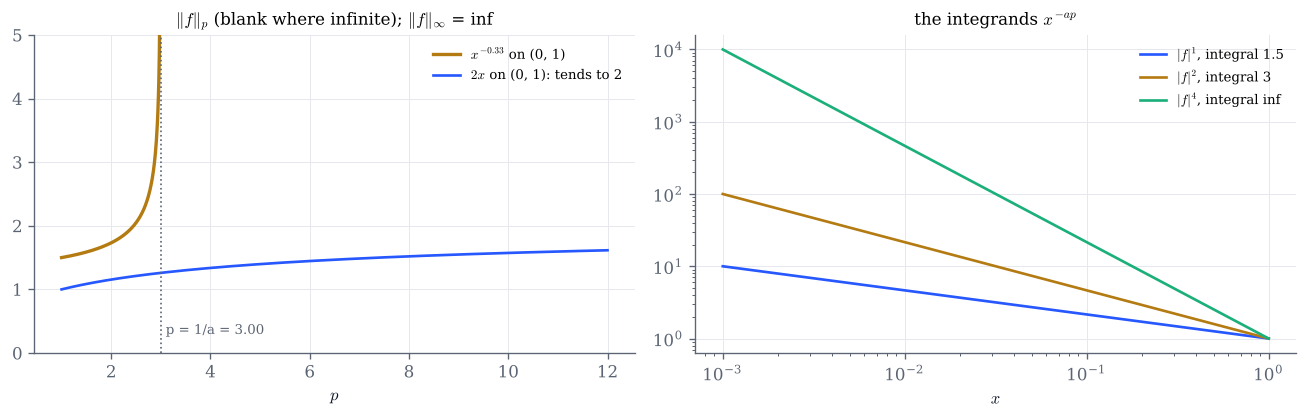

In [2]:
def lp_demo(a=1/3, domain="(0, 1)"):
    lo, hi = {"(0, 1)": (0.0, 1.0), "(1, inf)": (1.0, math.inf)}[domain]
    p = np.linspace(1, 12, 1101)
    norms = np.array([power_lp_norm(a, r, lo, hi) for r in p])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    finite = np.isfinite(norms)
    ax.plot(p[finite], norms[finite], color=GOLD, lw=2, label=f"$x^{{-{a:.2f}}}$ on {domain}")
    if domain == "(0, 1)":
        ax.plot(p, 2 / (p + 1) ** (1 / p), color=COBALT, label="$2x$ on (0, 1): tends to 2")
    ax.axvline(1 / a, color=GREY, ls=":", lw=1)
    ax.text(1 / a + 0.1, 0.3, f"p = 1/a = {1 / a:.2f}", color=GREY, fontsize=8)
    inf_sup = power_lp_norm(a, math.inf, lo, hi)
    ax.set(xlabel="$p$", ylim=(0, 5), title=f"$\\|f\\|_p$ (blank where infinite); $\\|f\\|_\\infty$ = {inf_sup:.3g}")
    ax.legend(fontsize=8)
    x = np.geomspace(1e-3, 1, 400) if domain == "(0, 1)" else np.geomspace(1, 1e3, 400)
    for r, c in ((1, COBALT), (2, GOLD), (4, GREEN)):
        ax2.plot(x, x ** (-a * r), color=c, label=f"$|f|^{{{r}}}$, integral {power_lp_norm(a, r, lo, hi) ** r:.3g}")
    ax2.set(xscale="log", yscale="log", xlabel="$x$", title="the integrands $x^{-ap}$")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

lp_demo()

In [3]:
# Explore: move a; on (1, inf) the norms are finite only for p > 1/a.
interact(lp_demo,
         a=FloatSlider(value=1/3, min=0.1, max=1.0, step=0.01, continuous_update=False, description="a"),
         domain=Dropdown(options=["(0, 1)", "(1, inf)"], value="(0, 1)", description="domain"));

## 2. Image measures on two dice

On $X=\{1,\dots,6\}^2$ with the uniform probability $\mu$, a map $\varphi$ pushes $\mu$ to its image measure
$\mu_\varphi(B)=\mu(\varphi^{-1}(B))$: the law of $\varphi$. Left: the 36 outcomes, coloured by the value of
$\varphi$. Right: $\mu_\varphi$. Below the plot, $\int g\,d\mu_\varphi=\int g\circ\varphi\,d\mu$ (Theorem 6.14)
for $g(y)=y$ and $g(y)=y^2$.

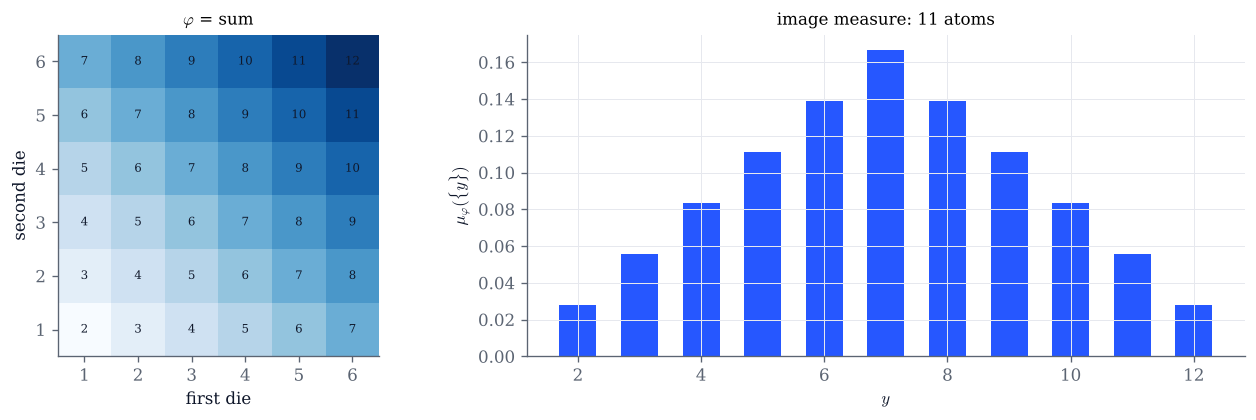

g(y) = y   : sum g dmu_phi = 7.000000,  sum g(phi) dmu = 7.000000
g(y) = y^2 : sum g dmu_phi = 54.833333,  sum g(phi) dmu = 54.833333


In [4]:
i, j = np.meshgrid(np.arange(1, 7), np.arange(1, 7), indexing="ij")
MAPS = {"sum": i + j, "max": np.maximum(i, j), "min": np.minimum(i, j),
        "|difference|": np.abs(i - j), "product": i * j, "first die": i}
w = np.full(36, 1 / 36)


def image_demo(phi="sum"):
    values = MAPS[phi]
    support, masses = image_measure(w, values.ravel())
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.6]})
    im = ax.imshow(values.T, origin="lower", cmap="Blues", extent=(0.5, 6.5, 0.5, 6.5))
    for a in range(1, 7):
        for b in range(1, 7):
            ax.text(a, b, str(values[a - 1, b - 1]), ha="center", va="center", fontsize=7, color=INK)
    ax.set(xlabel="first die", ylabel="second die", title=f"$\\varphi$ = {phi}")
    ax.grid(False)
    ax2.bar(support, masses, width=0.6 if len(support) < 20 else 0.8, color=COBALT)
    ax2.set(xlabel="$y$", ylabel="$\\mu_\\varphi(\\{y\\})$", title=f"image measure: {len(support)} atoms")
    fig.tight_layout()
    plt.show()
    for name, g in (("y", lambda y: y), ("y^2", lambda y: y**2)):
        print(f"g(y) = {name:4s}: sum g dmu_phi = {integral(g(support), masses):.6f},"
              f"  sum g(phi) dmu = {integral(g(values.ravel()), w):.6f}")

image_demo()

In [5]:
interact(image_demo, phi=Dropdown(options=list(MAPS), value="sum", description="phi"));

## 3. The empirical distribution function

Draw $n$ values from a law and compare the empirical distribution function $F_n(x)=\frac1n\#\{k:X_k\le x\}$ with
$F_X$. The band has half-width $\varepsilon=\sqrt{\ln(2/0.05)/(2n)}$: by the Dvoretzky–Kiefer–Wolfowitz inequality,
$F_n$ leaves it with probability at most 5% (Exercise 6.6). The samples are produced as image measures,
$F_X^{-1}(U)$ with $U$ uniform. The mixed law is the insurance payment of Exercise 6.10, in thousands.

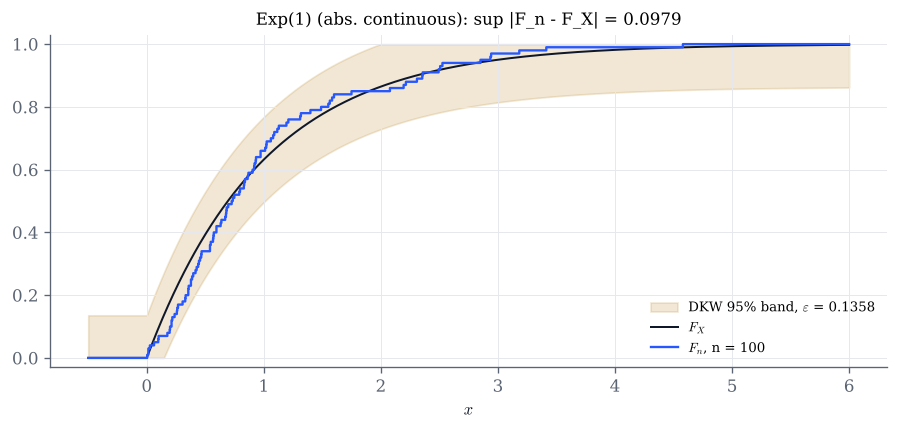

In [6]:
lam, d, u = 1.0, 0.5, 2.5
INSURANCE = MixedLaw([0.0, u], [1 - math.exp(-lam * d), math.exp(-lam * (d + u))],
                     lambda y: np.where((y > 0) & (y < u), lam * np.exp(-lam * (y + d)), 0.0), 0.0, u)
POIS = poisson_law(3.0)
TILE_F = lambda s: 0.5 + 0.75 * (np.clip(s - 10, -1, 1) - np.clip(s - 10, -1, 1) ** 3 / 3)
LAWS = {
    "Poisson(3) (discrete)": (POIS.cdf, POIS.cdf_left, lambda U: POIS.quantile(U), (-1, 11)),
    "Exp(1) (abs. continuous)": (lambda x: 1 - np.exp(-np.clip(x, 0, None)), None,
                                  lambda U: -np.log(1 - U), (-0.5, 6)),
    "tile side S (abs. continuous)": (TILE_F, None, lambda U: quantile(TILE_F, U, 9, 11), (8.8, 11.2)),
    "insurance payment (mixed)": (
        lambda y: np.where(y < 0, 0.0, np.where(y < u, 1 - np.exp(-lam * (d + np.clip(y, 0, u))), 1.0)),
        lambda y: np.where(y <= 0, 0.0, np.where(y <= u, 1 - np.exp(-lam * (d + np.clip(y, 0, u))), 1.0)),
        lambda U: np.minimum(np.maximum(-np.log(1 - U) / lam - d, 0.0), u),     # Y = h(L), L = F_L^{-1}(U)
        (-0.3, 2.8)),
}


def ecdf_demo(law="Exp(1) (abs. continuous)", log10_n=2.0, seed=2026):
    F, F_left, sampler, (a, b) = LAWS[law]
    n = int(10 ** log10_n)
    X = sampler(np.random.default_rng(seed).random(n))
    x = np.linspace(a, b, 2001)
    eps = dkw_epsilon(n, 0.05)
    D = ks_distance(X, F, F_left)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.fill_between(x, np.clip(F(x) - eps, 0, 1), np.clip(F(x) + eps, 0, 1), color=GOLD, alpha=0.18,
                    label=f"DKW 95% band, $\\varepsilon$ = {eps:.4f}")
    ax.plot(x, F(x), color=INK, lw=1.2, label="$F_X$")
    ax.step(x, ecdf(X, x), where="post", color=COBALT, lw=1.4, label=f"$F_n$, n = {n}")
    ax.set(xlabel="$x$", ylim=(-0.03, 1.03), title=f"{law}: sup |F_n - F_X| = {D:.4f}")
    ax.legend(fontsize=8, loc="lower right")
    plt.show()

ecdf_demo()

In [7]:
interact(ecdf_demo,
         law=Dropdown(options=list(LAWS), value="Exp(1) (abs. continuous)", description="law"),
         log10_n=FloatSlider(value=2.0, min=1.0, max=5.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## 4. Radon–Nikodym derivatives between discrete laws

On $\mathbb N$, $\nu\ll\mu$ when $\nu$ charges no point that $\mu$ does not charge, and then
$\frac{d\nu}{d\mu}(k)=\nu(\{k\})/\mu(\{k\})$. Here $\nu=B(n,p)$ and $\mu$ is a Poisson law $\mathcal P(\lambda)$
(which charges every $k$) or a binomial $B(n,q)$. The derivative reweights $\mu$ into $\nu$:
$\int g\,d\nu=\int g\frac{d\nu}{d\mu}\,d\mu$ (Proposition 6.25).

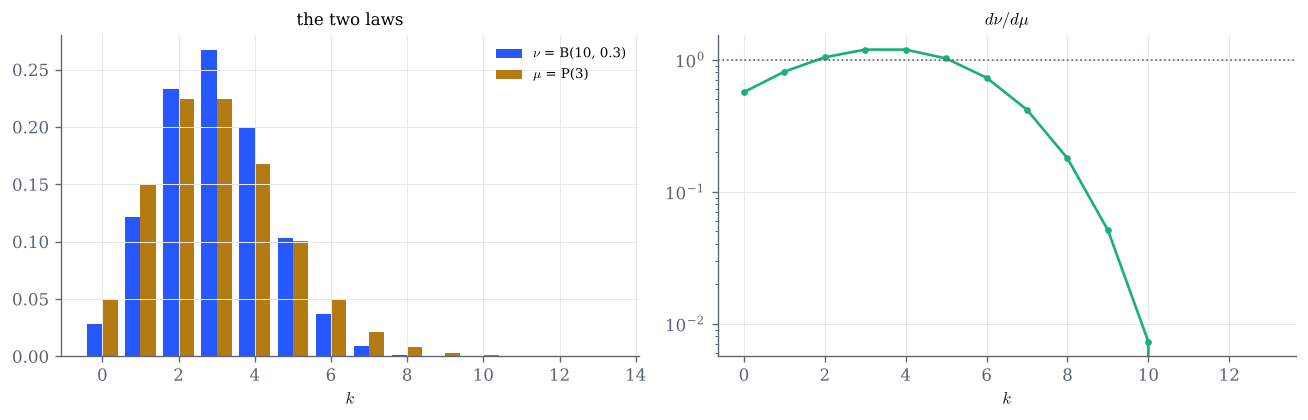

int k dnu = 3.000000 = sum k f(k) mu(k) = 3.000000;  mu << nu: False


In [8]:
def rn_demo(n=10, p=0.3, reference="Poisson", lam=3.0, q=0.5):
    k = np.arange(0, max(3 * n, 40) + 1)
    nu = stats.binom.pmf(k, n, p)
    mu = stats.poisson.pmf(k, lam) if reference == "Poisson" else stats.binom.pmf(k, n, q)
    name = f"P({lam:g})" if reference == "Poisson" else f"B({n}, {q:g})"
    show = k <= max(n, int(lam + 5 * math.sqrt(lam))) + 2
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    ax.bar(k[show] - 0.2, nu[show], width=0.4, color=COBALT, label=f"$\\nu$ = B({n}, {p:g})")
    ax.bar(k[show] + 0.2, mu[show], width=0.4, color=GOLD, label=f"$\\mu$ = {name}")
    ax.set(xlabel="$k$", title="the two laws")
    ax.legend(fontsize=8)
    if is_absolutely_continuous(nu, mu):
        f = radon_nikodym(nu, mu)
        ax2.plot(k[show], f[show], "o-", color=GREEN, ms=3)
        ax2.axhline(1, color=GREY, ls=":", lw=1)
        ax2.set(xlabel="$k$", yscale="log", title="$d\\nu/d\\mu$")
        msg = (f"int k dnu = {integral(k, nu):.6f} = sum k f(k) mu(k) = {integral(k * f, mu):.6f};  "
               f"mu << nu: {is_absolutely_continuous(mu, nu)}")
    else:
        ax2.text(0.5, 0.5, "$\\nu$ is not absolutely continuous\\nwith respect to $\\mu$: no density",
                 ha="center", va="center", transform=ax2.transAxes)
        msg = "nu charges points of mu-measure 0"
    fig.tight_layout()
    plt.show()
    print(msg)

rn_demo()

In [9]:
# Explore: with a binomial reference B(n, q), d nu / d mu = (p/q)^k ((1-p)/(1-q))^(n-k).
interact(rn_demo,
         n=IntSlider(value=10, min=1, max=40, continuous_update=False, description="n"),
         p=FloatSlider(value=0.3, min=0.02, max=0.98, step=0.02, continuous_update=False, description="p"),
         reference=Dropdown(options=["Poisson", "binomial"], value="Poisson", description="mu"),
         lam=FloatSlider(value=3.0, min=0.5, max=20, step=0.5, continuous_update=False, description="lambda"),
         q=FloatSlider(value=0.5, min=0.02, max=0.98, step=0.02, continuous_update=False, description="q"));

## 5. $\mathbb E[g(X)]$ three ways

$\mathbb E[g(X)]=\int_\Omega g(X)\,d\mathbb P=\int_{\mathbb R}g\,d\mathbb P_X=\int g(x)f_X(x)\,dx$ (formula (6.8)). The
running Monte Carlo average of $g(X_1),\dots,g(X_k)$, with its 95% band, against the exact value computed with
the density (or, for the mixed law, with its atoms and its density).

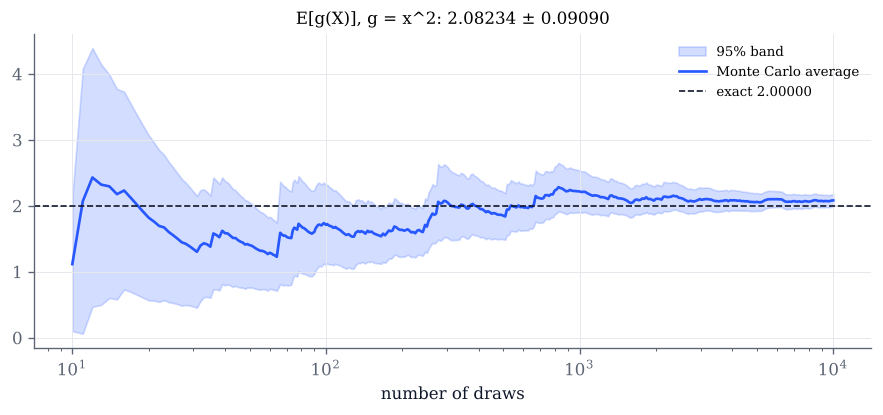

In [10]:
GS = {"x": lambda x: x, "x^2": lambda x: x**2, "1(x > 1)": lambda x: np.where(np.asarray(x) > 1, 1.0, 0.0), "cos x": np.cos}
EXACT = {
    "Exp(1) (abs. continuous)": lambda g: expectation_density(g, lambda x: np.exp(-x), 0, math.inf, points=[1.0]),
    "tile side S (abs. continuous)": lambda g: expectation_density(g, lambda s: 0.75 * (1 - (s - 10) ** 2), 9, 11),
    "insurance payment (mixed)": lambda g: INSURANCE.expectation(g),
}


def mc_demo(law="Exp(1) (abs. continuous)", g="x^2", log10_n=4.0, seed=2026):
    n = int(10 ** log10_n)
    X = LAWS[law][2](np.random.default_rng(seed).random(n))
    y = GS[g](X)
    k = np.arange(1, n + 1)
    run = np.cumsum(y) / k
    sd = np.sqrt(np.maximum(np.cumsum(y**2) / k - run**2, 0) / k)
    exact = EXACT[law](GS[g])
    idx = np.unique(np.geomspace(10, n, 400).astype(int)) - 1
    fig, ax = plt.subplots(figsize=(9, 3.4))
    ax.fill_between(k[idx], run[idx] - 1.96 * sd[idx], run[idx] + 1.96 * sd[idx], color=COBALT, alpha=0.2,
                    label="95% band")
    ax.plot(k[idx], run[idx], color=COBALT, label="Monte Carlo average")
    ax.axhline(exact, color=INK, ls="--", lw=1, label=f"exact {exact:.5f}")
    ax.set(xscale="log", xlabel="number of draws", title=f"E[g(X)], g = {g}: {run[-1]:.5f} ± {1.96 * sd[-1]:.5f}")
    ax.legend(fontsize=8)
    plt.show()

mc_demo()

In [11]:
interact(mc_demo,
         law=Dropdown(options=list(EXACT), value="Exp(1) (abs. continuous)", description="law"),
         g=Dropdown(options=list(GS), value="x^2", description="g"),
         log10_n=FloatSlider(value=4.0, min=2.0, max=6.0, step=0.25, continuous_update=False, description="log10 n"),
         seed=IntSlider(value=2026, min=0, max=3000, continuous_update=False, description="seed"));

## Things to try

- In section 1, take $a\in(1/4,1/2)$ and check that $x^{-a}$ is in $L^2(0,1)$ but not in $L^4(0,1)$, and in $L^4(1,\infty)$ but not in $L^2(1,\infty)$. What changes at $a=1/4$ and at $a=1/2$?
- In section 2, which map has the most atoms? For which maps is $\mu_\varphi$ uniform?
- In section 3, take $n=10^{4.25}\approx18\,000$ (the sample size of Exercise 6.6) and change the seed: how often does $F_n$ leave the band for the exponential law? And for the Poisson law?
- In section 3, the mixed law has two jumps. Does $F_n$ jump at the same places?
- In section 4, set the reference to $B(n,q)$ with $q=p$: what is $d\nu/d\mu$? Then make $\lambda$ very small: why does the derivative explode in the right tail?
- In section 5, why does the band for $g=1(x>1)$ never shrink faster than $1/\sqrt n$, whatever the law?